# مشروع تعلم الآلة النهائي
## التنبؤ بتأخر الطالب في سداد القسط الدراسي

يهدف المشروع إلى بناء نظام تعلم آلة يتنبأ باحتمالية تأخر الطالب في سداد القسط الدراسي.

يمر المشروع بالمراحل التالية:

1. قراءة البيانات.
2. فهم البيانات.
3. تنظيف البيانات.
4. معالجة القيم المفقودة.
5. معالجة القيم غير المنطقية والشاذة.
6. التحليل الاستكشافي EDA.
7. تجهيز البيانات للتعلم الآلي.
8. تقسيم البيانات إلى Training و Testing.
9. معالجة البيانات باستخدام Pipeline.
10. تجربة عدة خوارزميات.
11. مقارنة النماذج.
12. ضبط Hyperparameters.
13. اختيار أفضل نموذج.
14. تقييم النموذج النهائي.
15. استخراج أهم العوامل المؤثرة.
16. حفظ النموذج.
17. حفظ نتائج مقارنة النماذج للواجهة.
18. تجهيز النموذج للاستخدام مع FastAPI.

## تعريف الحالة الإيجابية

في هذا المشروع:

- `0` = الطالب دفع القسط في موعده.
- `1` = الطالب تأخر في دفع القسط.

وبالتالي فإن Precision و Recall و F1-score سيتم حسابها بالنسبة للطالب المتأخر.

# 1. تثبيت المكتبات

إذا كانت إحدى المكتبات غير موجودة يمكن تثبيتها باستخدام الخلية التالية.

# شغل هذا السطر فقط إذا كانت المكتبات غير مثبتة

# !pip install pandas numpy matplotlib scikit-learn openpyxl joblib

# 2. استيراد المكتبات

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.inspection import permutation_importance


warnings.filterwarnings("ignore")

RANDOM_STATE = 42


pd.set_option(
    "display.max_columns",
    100
)

pd.set_option(
    "display.max_rows",
    100
)


print("تم تحميل المكتبات بنجاح")

تم تحميل المكتبات بنجاح


# 3. تحديد مسارات المشروع

هيكل المشروع المتوقع:

project/

- data/
- models/
- notebooks/
- backend/
- frontend/
- research/

ويجب وضع ملف البيانات داخل:

data/dataset-students.xlsx

In [2]:
cwd = Path.cwd()


possible_paths = [

    cwd / "data" / "dataset-students.xlsx",

    cwd.parent / "data" / "dataset-students.xlsx",

    cwd / "dataset-students.xlsx"
]


DATA_PATH = None


for path in possible_paths:

    if path.exists():

        DATA_PATH = path

        break


if DATA_PATH is None:

    raise FileNotFoundError(
        "لم يتم العثور على dataset-students.xlsx"
    )


if DATA_PATH.parent.name == "data":

    PROJECT_ROOT = DATA_PATH.parent.parent

else:

    PROJECT_ROOT = cwd


DATA_DIR = PROJECT_ROOT / "data"

MODELS_DIR = PROJECT_ROOT / "models"

RESEARCH_DIR = PROJECT_ROOT / "research"

FIGURES_DIR = RESEARCH_DIR / "figures"


DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)


MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("PROJECT ROOT:")
print(PROJECT_ROOT)

print("\nDATA PATH:")
print(DATA_PATH)

print("\nMODELS DIRECTORY:")
print(MODELS_DIR)

print("\nFIGURES DIRECTORY:")
print(FIGURES_DIR)

PROJECT ROOT:
C:\Users\abdalmohaymen\Downloads\mlproject

DATA PATH:
C:\Users\abdalmohaymen\Downloads\mlproject\data\dataset-students.xlsx

MODELS DIRECTORY:
C:\Users\abdalmohaymen\Downloads\mlproject\models

FIGURES DIRECTORY:
C:\Users\abdalmohaymen\Downloads\mlproject\research\figures


# 4. قراءة البيانات

In [3]:
df_raw = pd.read_excel(
    DATA_PATH
)


print(
    "عدد الصفوف:",
    df_raw.shape[0]
)


print(
    "عدد الأعمدة:",
    df_raw.shape[1]
)


df_raw.head()

عدد الصفوف: 264
عدد الأعمدة: 22


,طابع زمني,الفرع,قيمة القسط التقريببة,من المسؤول عن دفع القسط,هل تعمل الى جانب الدراسة,المحافظة,عدد الساعات لمسجل عليها,هل سبق وأن تأخر في سداد القسط عن الموعد المحدد,المعدل التراكمي التقريبي من 100,نسبة الحضور في جميع المقررات من 100,عدد المرات التي تأخرت بها عن تسديد القسط,اقصى مدة زمنية تأخرت بها عن تسديد القسط بالايام,عدد المرات التي لم تتأخر بها عن تسديد القسط,الدخل المالي الشهري للعائلة بالدولار حصرا,عدد الاخوة والاخوات الطلاب في التعليم الجامعي الخاص,قيمة القسط الفصلي بشكل تقديري,هل سددت القسط الأخير في موعده,السنة الدراسية,عدد الاشخاص العاملين بالاسرة,هل توجد أقساط جامعية سابقة غير مسددة,السكن,بعد سكن الطالب عن مركز الجامعة بالكيلو متر
0,2026-08-17 03:33:16.711,الهندسة المعلوماتية,NaN,الطالب,نعم,ادلب,6.0,نعم,65.0,50,2.0,10.0,10,بين 100 و 200,1.000000,150.0,نعم,خامسة,2.0,نعم,ملك,100.0
1,2026-08-17 03:33:59.547,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),نعم,حلب,9.0,نعم,70.0,90,3.0,2.0,10,بين 100 و 200,1.000000,150.0,نعم,خامسة,1.0,لا,ملك,3.0
2,2026-08-17 03:35:00.270,معلوماتيه,NaN,الأسرة(اب-أم),لا,حلب,9.0,لا,75.0,75,1.0,1.0,6,اقل من 100,1.000000,400.0,نعم,ثالثة,1.0,لا,ملك,5.0
3,2026-08-17 03:36:31.111,هندسة معلوماتية,NaN,الأسرة(اب-أم),لا,ادلب,18.0,لا,85.0,95,1.0,3.0,8,بين 200 و 500,0.000001,200.0,نعم,رابعة,2.0,لا,ايجار,7.0
4,2026-08-17 03:36:38.551,هندسة معلوماتية,NaN,الطالب,نعم,حلب,117.0,نعم,80.0,40,2.0,15.0,5,بين 200 و 500,1.000000,400.0,نعم,ثالثة,3.0,لا,ملك,40.0


# 5. الفحص الأولي للبيانات

In [4]:
print(
    "Shape:",
    df_raw.shape
)


print(
    "\nعدد الصفوف المكررة:",
    df_raw.duplicated().sum()
)

Shape: (264, 22)

عدد الصفوف المكررة: 3


In [5]:
for i, col in enumerate(
    df_raw.columns,
    start=1
):

    print(
        f"{i:02d}. {repr(col)}"
    )

01. 'طابع زمني'
02. 'الفرع'
03. 'قيمة القسط التقريببة'
04. 'من المسؤول عن دفع القسط'
05. 'هل تعمل الى جانب الدراسة'
06. 'المحافظة'
07. 'عدد الساعات لمسجل عليها'
08. 'هل سبق وأن تأخر في سداد القسط عن الموعد المحدد'
09. 'المعدل التراكمي التقريبي من 100'
10. 'نسبة الحضور في جميع المقررات من 100'
11. 'عدد المرات التي تأخرت بها عن تسديد القسط'
12. 'اقصى مدة زمنية تأخرت بها عن تسديد القسط بالايام '
13. 'عدد المرات التي لم تتأخر بها عن تسديد القسط'
14. 'الدخل المالي الشهري للعائلة بالدولار حصرا '
15. 'عدد الاخوة والاخوات الطلاب في التعليم الجامعي الخاص '
16. 'قيمة القسط الفصلي بشكل تقديري'
17. '  هل سددت القسط الأخير في موعده  '
18. 'السنة الدراسية'
19. 'عدد الاشخاص العاملين بالاسرة'
20. 'هل توجد أقساط جامعية سابقة غير مسددة'
21. 'السكن'
22. 'بعد سكن الطالب عن مركز الجامعة بالكيلو متر'


In [6]:
initial_summary = pd.DataFrame({

    "dtype":
        df_raw.dtypes.astype(str),

    "missing_count":
        df_raw.isna().sum(),

    "missing_percent":
        (
            df_raw.isna().mean()
            * 100
        ).round(2),

    "unique_values":
        df_raw.nunique(
            dropna=False
        )

})


initial_summary.sort_values(
    "missing_percent",
    ascending=False
)

,dtype,missing_count,missing_percent,unique_values
قيمة القسط التقريببة,float64,65,24.62,37
عدد الساعات لمسجل عليها,float64,3,1.14,13
بعد سكن الطالب عن مركز الجامعة بالكيلو متر,float64,1,0.38,215
الدخل المالي الشهري للعائلة بالدولار حصرا,object,1,0.38,7
عدد الاشخاص العاملين بالاسرة,float64,1,0.38,8
المعدل التراكمي التقريبي من 100,float64,1,0.38,128
السكن,object,0,0.00,6
هل توجد أقساط جامعية سابقة غير مسددة,object,0,0.00,3
السنة الدراسية,object,0,0.00,6
هل سددت القسط الأخير في موعده,object,0,0.00,2


# 6. إعادة تسمية الأعمدة

سنحول أسماء الأعمدة العربية الطويلة إلى أسماء إنجليزية مختصرة لتسهيل استخدامها في البرمجة وفي FastAPI لاحقًا.

In [7]:
COLUMN_RENAME_MAP = {

    "طابع زمني":
        "timestamp",

    "الفرع":
        "branch",

    "قيمة القسط التقريببة":
        "approx_installment_value",

    "من المسؤول عن دفع القسط":
        "payment_responsible",

    "هل تعمل الى جانب الدراسة":
        "works_while_studying",

    "المحافظة":
        "governorate",

    "عدد الساعات لمسجل عليها":
        "registered_hours",

    "هل سبق وأن تأخر في سداد القسط عن الموعد المحدد":
        "previous_payment_delay",

    "المعدل التراكمي التقريبي من 100":
        "gpa",

    "نسبة الحضور في جميع المقررات من 100":
        "attendance_rate",

    "عدد المرات التي تأخرت بها عن تسديد القسط":
        "delay_count",

    "اقصى مدة زمنية تأخرت بها عن تسديد القسط بالايام ":
        "max_delay_days",

    "عدد المرات التي لم تتأخر بها عن تسديد القسط":
        "on_time_payment_count",

    "الدخل المالي الشهري للعائلة بالدولار حصرا ":
        "family_monthly_income",

    "عدد الاخوة والاخوات الطلاب في التعليم الجامعي الخاص ":
        "private_university_siblings",

    "قيمة القسط الفصلي بشكل تقديري":
        "semester_fee",

    "  هل سددت القسط الأخير في موعده  ":
        "paid_last_installment_on_time",

    "السنة الدراسية":
        "study_year",

    "عدد الاشخاص العاملين بالاسرة":
        "working_family_members",

    "هل توجد أقساط جامعية سابقة غير مسددة":
        "previous_unpaid_fees",

    "السكن":
        "housing",

    "بعد سكن الطالب عن مركز الجامعة بالكيلو متر":
        "distance_from_university"
}


df = df_raw.rename(
    columns=COLUMN_RENAME_MAP
).copy()


df.head()

,timestamp,branch,approx_installment_value,payment_responsible,works_while_studying,governorate,registered_hours,previous_payment_delay,gpa,attendance_rate,delay_count,max_delay_days,on_time_payment_count,family_monthly_income,private_university_siblings,semester_fee,paid_last_installment_on_time,study_year,working_family_members,previous_unpaid_fees,housing,distance_from_university
0,2026-08-17 03:33:16.711,الهندسة المعلوماتية,NaN,الطالب,نعم,ادلب,6.0,نعم,65.0,50,2.0,10.0,10,بين 100 و 200,1.000000,150.0,نعم,خامسة,2.0,نعم,ملك,100.0
1,2026-08-17 03:33:59.547,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),نعم,حلب,9.0,نعم,70.0,90,3.0,2.0,10,بين 100 و 200,1.000000,150.0,نعم,خامسة,1.0,لا,ملك,3.0
2,2026-08-17 03:35:00.270,معلوماتيه,NaN,الأسرة(اب-أم),لا,حلب,9.0,لا,75.0,75,1.0,1.0,6,اقل من 100,1.000000,400.0,نعم,ثالثة,1.0,لا,ملك,5.0
3,2026-08-17 03:36:31.111,هندسة معلوماتية,NaN,الأسرة(اب-أم),لا,ادلب,18.0,لا,85.0,95,1.0,3.0,8,بين 200 و 500,0.000001,200.0,نعم,رابعة,2.0,لا,ايجار,7.0
4,2026-08-17 03:36:38.551,هندسة معلوماتية,NaN,الطالب,نعم,حلب,117.0,نعم,80.0,40,2.0,15.0,5,بين 200 و 500,1.000000,400.0,نعم,ثالثة,3.0,لا,ملك,40.0


In [8]:
df.columns.tolist()

['timestamp',
 'branch',
 'approx_installment_value',
 'payment_responsible',
 'works_while_studying',
 'governorate',
 'registered_hours',
 'previous_payment_delay',
 'gpa',
 'attendance_rate',
 'delay_count',
 'max_delay_days',
 'on_time_payment_count',
 'family_monthly_income',
 'private_university_siblings',
 'semester_fee',
 'paid_last_installment_on_time',
 'study_year',
 'working_family_members',
 'previous_unpaid_fees',
 'housing',
 'distance_from_university']

# 7. تنظيف البيانات النصية

سنزيل:

- المسافات في بداية ونهاية النص.
- المسافات المكررة.
- المحارف المخفية.

In [9]:
def clean_text(value):

    if pd.isna(value):

        return np.nan


    value = str(value)


    value = value.replace(
        "\u200f",
        ""
    )


    value = value.replace(
        "\u200e",
        ""
    )


    value = value.replace(
        "\xa0",
        " "
    )


    value = re.sub(
        r"\s+",
        " ",
        value
    )


    value = value.strip()


    return value

In [10]:
object_columns = df.select_dtypes(
    include="object"
).columns


for col in object_columns:

    df[col] = df[col].map(
        clean_text
    )


print(
    "تم تنظيف النصوص"
)

تم تنظيف النصوص


## 7.1 فحص القيم الفئوية

سنطبع القيم المختلفة داخل كل عمود نصي حتى نكتشف الأخطاء الكتابية.

In [11]:
for col in df.select_dtypes(
    include="object"
).columns:

    print(
        "\n" + "=" * 80
    )

    print(col)

    print(
        df[col].value_counts(
            dropna=False
        )
    )


branch
branch
كلية الهندسة المعلوماتية       52
معهد أمن المعلومات والشبكات    28
كلية الهندسة المدنية           20
كلية التمريض                   19
هندسة معلوماتية                19
كلية الصيدلة                   19
كلية إدارة الأعمال             18
كلية الهندسة المعمارية         18
معهد نظم المعلومات الإدارية    18
الهندسة المعلوماتية            11
كلية الحقوق                    11
كلية الاقتصاد                  10
معلوماتية                       3
معهد امن المعلومات              2
هندسه معلوماتية                 2
الهندسة                         1
هندسة معلوماتيه                 1
نظم المعلومات الإدارية          1
مصطفى محمد السماعيل             1
هتدسة معلوماتية                 1
كلية هندسة معلوماتية            1
معلوطاتية                       1
احمد عبد الله عبد القادر        1
أمن معلومات وشبكات              1
الهندسه المعلوماتية             1
هندسة المعلوماتية               1
المعلوماتية                     1
معلوماتيه                       1
كلية الهندسة المعلومايتة        1

# 8. معالجة الأخطاء الكتابية في البيانات الفئوية

In [12]:
branch_replacements = {

    "هندسة معلوماتية":
        "كلية الهندسة المعلوماتية",

    "الهندسة المعلوماتية":
        "كلية الهندسة المعلوماتية",

    "الهندسه المعلوماتية":
        "كلية الهندسة المعلوماتية",

    "هندسة المعلوماتية":
        "كلية الهندسة المعلوماتية",

    "معلوماتية":
        "كلية الهندسة المعلوماتية",

    "معلوماتيه":
        "كلية الهندسة المعلوماتية",

    "المعلوماتية":
        "كلية الهندسة المعلوماتية",

    "هندسة معلوماتيه":
        "كلية الهندسة المعلوماتية",

    "هندسه معلوماتية":
        "كلية الهندسة المعلوماتية",

    "كلية هندسة معلوماتية":
        "كلية الهندسة المعلوماتية",

    "كلية الهندسة المعلومايتة":
        "كلية الهندسة المعلوماتية",

    "هتدسة معلوماتية":
        "كلية الهندسة المعلوماتية",

    "معلوطاتية":
        "كلية الهندسة المعلوماتية",

    "معهد امن المعلومات":
        "معهد أمن المعلومات والشبكات",

    "أمن معلومات وشبكات":
        "معهد أمن المعلومات والشبكات",

    "نظم المعلومات الإدارية":
        "معهد نظم المعلومات الإدارية"
}


df["branch"] = df[
    "branch"
].replace(
    branch_replacements
)

In [13]:
invalid_branch_values = {

    "احمد عبد الله عبد القادر",

    "مصطفى محمد السماعيل",

    "الهندسة"
}


df.loc[
    df["branch"].isin(
        invalid_branch_values
    ),
    "branch"
] = np.nan

In [14]:
df["payment_responsible"] = (
    df["payment_responsible"]
    .replace({

        "الاسرة":
            "الأسرة(اب-أم)"

    })
)

In [15]:
df["governorate"] = (
    df["governorate"]
    .replace({

        "ادلب":
            "إدلب",

        "حماه":
            "حماة",

        "حلبب":
            "حلب"

    })
)

In [16]:
df["family_monthly_income"] = (
    df["family_monthly_income"]
    .replace({

        "بين 200-500":
            "بين 200 و 500"

    })
)

In [17]:
df["family_monthly_income"] = (
    df["family_monthly_income"]
    .replace({

        "بين 200-500":
            "بين 200 و 500"

    })
)

In [18]:
df["study_year"] = (
    df["study_year"]
    .replace({

        "سنة أولى":
            "أولى"

    })
)

In [19]:
columns_to_check = [

    "branch",

    "payment_responsible",

    "governorate",

    "family_monthly_income",

    "study_year",

    "housing"
]


for col in columns_to_check:

    print(
        "\n" + "=" * 60
    )

    print(col)

    print(
        df[col].value_counts(
            dropna=False
        )
    )


branch
branch
كلية الهندسة المعلوماتية       96
معهد أمن المعلومات والشبكات    31
كلية الهندسة المدنية           20
معهد نظم المعلومات الإدارية    19
كلية الصيدلة                   19
كلية التمريض                   19
كلية الهندسة المعمارية         18
كلية إدارة الأعمال             18
كلية الحقوق                    11
كلية الاقتصاد                  10
NaN                             3
Name: count, dtype: int64

payment_responsible
payment_responsible
الأسرة(اب-أم)     119
الطالب            108
الطالب والأسرة     29
منحة/جهة داعمة      8
Name: count, dtype: int64

governorate
governorate
إدلب         84
حلب          72
حماة         23
حمص          17
دمشق         16
اللاذقية     11
الحسكة        9
دير الزور     8
طرطوس         8
الرقة         8
السويداء      4
درعا          2
القنيطرة      2
Name: count, dtype: int64

family_monthly_income
family_monthly_income
بين 200 و 500     112
بين 100 و 200      61
بين 500 و 1000     52
اقل من 100         23
اكثر من 1000       15
NaN             

# 9. التأكد من الأعمدة الرقمية

سنستخدم pd.to_numeric.

أي قيمة غير قابلة للتحويل ستتحول إلى NaN.

In [20]:
EXPECTED_NUMERIC_COLUMNS = [

    "approx_installment_value",

    "registered_hours",

    "gpa",

    "attendance_rate",

    "delay_count",

    "max_delay_days",

    "on_time_payment_count",

    "private_university_siblings",

    "semester_fee",

    "working_family_members",

    "distance_from_university"
]


for col in EXPECTED_NUMERIC_COLUMNS:

    df[col] = pd.to_numeric(

        df[col],

        errors="coerce"

    )

In [21]:
df[
    EXPECTED_NUMERIC_COLUMNS
].dtypes

approx_installment_value       float64
registered_hours               float64
gpa                            float64
attendance_rate                  int64
delay_count                    float64
max_delay_days                 float64
on_time_payment_count            int64
private_university_siblings    float64
semester_fee                   float64
working_family_members         float64
distance_from_university       float64
dtype: object

# 10. معالجة القيم غير المنطقية

لن نحذف كل Outlier.

سنحوّل فقط القيم الواضح أنها أخطاء إدخال إلى NaN.

أمثلة:

- المعدل أكبر من 100.
- الحضور أكبر من 100.
- الساعات المسجلة أكبر من 30.
- مسافة سالبة.
- مسافة غير منطقية مثل 8000 كم.

In [22]:
invalid_value_report = {}


rules = {

    "approx_installment_value":

        (
            df["approx_installment_value"]
            <= 0
        ),


    "registered_hours":

        (
            (
                df["registered_hours"]
                < 0
            )
            |
            (
                df["registered_hours"]
                > 30
            )
        ),


    "gpa":

        (
            (
                df["gpa"]
                < 0
            )
            |
            (
                df["gpa"]
                > 100
            )
        ),


    "attendance_rate":

        (
            (
                df["attendance_rate"]
                < 0
            )
            |
            (
                df["attendance_rate"]
                > 100
            )
        ),


    "delay_count":

        (
            df["delay_count"]
            < 0
        ),


    "max_delay_days":

        (
            df["max_delay_days"]
            < 0
        ),


    "on_time_payment_count":

        (
            df["on_time_payment_count"]
            < 0
        ),


    "private_university_siblings":

        (
            df[
                "private_university_siblings"
            ]
            < 0
        ),


    "semester_fee":

        (
            df["semester_fee"]
            <= 10
        ),


    "working_family_members":

        (
            df[
                "working_family_members"
            ]
            < 0
        ),


    "distance_from_university":

        (
            (
                df[
                    "distance_from_university"
                ]
                < 0
            )
            |
            (
                df[
                    "distance_from_university"
                ]
                > 1000
            )
        )
}

In [23]:
for col, mask in rules.items():

    count = int(
        mask.fillna(
            False
        ).sum()
    )


    invalid_value_report[
        col
    ] = count


    df.loc[
        mask,
        col
    ] = np.nan

In [24]:
pd.DataFrame(

    invalid_value_report.items(),

    columns=[
        "column",
        "invalid_values_converted_to_nan"
    ]

)

,column,invalid_values_converted_to_nan
0,approx_installment_value,0
1,registered_hours,4
2,gpa,0
3,attendance_rate,1
4,delay_count,0
5,max_delay_days,0
6,on_time_payment_count,0
7,private_university_siblings,0
8,semester_fee,2
9,working_family_members,0


# 11. معالجة التناقضات الداخلية

لدينا:

- previous_payment_delay
- delay_count
- max_delay_days

إذا كان delay_count أكبر من صفر أو max_delay_days أكبر من صفر، فهذا يعني أن الطالب سبق أن تأخر.

In [25]:
before_consistency = (
    df[
        "previous_payment_delay"
    ].copy()
)


history_known = (

    df["delay_count"].notna()

    &

    df["max_delay_days"].notna()

)

In [26]:
has_previous_delay = (

    history_known

    &

    (
        (
            df["delay_count"]
            > 0
        )

        |

        (
            df["max_delay_days"]
            > 0
        )
    )

)

In [27]:
has_no_previous_delay = (

    history_known

    &

    (
        df["delay_count"]
        == 0
    )

    &

    (
        df["max_delay_days"]
        == 0
    )

)

In [28]:
df.loc[

    has_previous_delay,

    "previous_payment_delay"

] = "نعم"


df.loc[

    has_no_previous_delay,

    "previous_payment_delay"

] = "لا"

In [29]:
consistency_changes = int(

    (
        before_consistency
        !=
        df[
            "previous_payment_delay"
        ]
    )
    .fillna(False)
    .sum()

)


print(
    "عدد القيم المصححة:",
    consistency_changes
)

عدد القيم المصححة: 89


# 12. حذف الصفوف المكررة

لن نستخدم timestamp لتحديد التكرار لأن طالبين متطابقين في البيانات قد تكون لديهما أوقات إرسال مختلفة.

In [30]:
before_rows = len(df)


duplicate_subset = [

    col

    for col in df.columns

    if col != "timestamp"

]

In [31]:
duplicate_count = int(

    df.duplicated(

        subset=duplicate_subset,

        keep="first"

    ).sum()

)


print(
    "عدد التكرارات:",
    duplicate_count
)

عدد التكرارات: 3


In [32]:
df = df.drop_duplicates(

    subset=duplicate_subset,

    keep="first"

).reset_index(
    drop=True
)


after_rows = len(df)


print(
    "عدد الصفوف قبل:",
    before_rows
)


print(
    "عدد الصفوف بعد:",
    after_rows
)

عدد الصفوف قبل: 264
عدد الصفوف بعد: 261


# 13. القيم المفقودة

In [33]:
missing_after_cleaning = pd.DataFrame({

    "missing_count":
        df.isna().sum(),

    "missing_percent":
        (
            df.isna().mean()
            * 100
        ).round(2)

})


missing_after_cleaning.sort_values(

    "missing_percent",

    ascending=False

)

,missing_count,missing_percent
approx_installment_value,65,24.90
registered_hours,7,2.68
distance_from_university,3,1.15
branch,3,1.15
semester_fee,2,0.77
working_family_members,1,0.38
gpa,1,0.38
attendance_rate,1,0.38
family_monthly_income,1,0.38
private_university_siblings,0,0.00


لن نملأ القيم المفقودة الآن.

سيتم تنفيذ Imputation داخل Pipeline بعد تقسيم البيانات.

الهدف من ذلك هو منع Data Leakage.

# 14. اكتشاف القيم الشاذة باستخدام IQR

سنكشف القيم الشاذة فقط، ولن نحذفها تلقائيًا.

In [34]:
def iqr_outlier_report(
    dataframe,
    columns
):

    rows = []


    for col in columns:

        s = dataframe[
            col
        ].dropna()


        if len(s) == 0:

            continue


        q1 = s.quantile(
            0.25
        )


        q3 = s.quantile(
            0.75
        )


        iqr = q3 - q1


        lower_bound = (
            q1
            -
            1.5 * iqr
        )


        upper_bound = (
            q3
            +
            1.5 * iqr
        )


        outlier_count = int(

            (
                (s < lower_bound)

                |

                (s > upper_bound)
            ).sum()

        )


        rows.append({

            "column":
                col,

            "Q1":
                q1,

            "Q3":
                q3,

            "IQR":
                iqr,

            "lower_bound":
                lower_bound,

            "upper_bound":
                upper_bound,

            "outlier_count":
                outlier_count

        })


    return pd.DataFrame(
        rows
    ).sort_values(

        "outlier_count",

        ascending=False

    )

In [35]:
numeric_columns_now = (

    df.select_dtypes(
        include=np.number
    )
    .columns
    .tolist()

)


outlier_report = iqr_outlier_report(

    df,

    numeric_columns_now

)


outlier_report

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
4,delay_count,1.000000,2.000,1.000000,-0.500000,3.500000,43
5,max_delay_days,1.000000,10.000,9.000000,-12.500000,23.500000,32
3,attendance_rate,69.000000,87.000,18.000000,42.000000,114.000000,13
2,gpa,70.000000,82.000,12.000000,52.000000,100.000000,8
8,semester_fee,176.500000,289.500,113.000000,7.000000,459.000000,5
0,approx_installment_value,95.000000,155.000,60.000000,5.000000,245.000000,3
1,registered_hours,9.000000,15.000,6.000000,0.000000,24.000000,2
6,on_time_payment_count,4.000000,9.000,5.000000,-3.500000,16.500000,2
7,private_university_siblings,0.000001,2.000,1.999999,-2.999998,4.999999,1
9,working_family_members,1.000000,3.000,2.000000,-2.000000,6.000000,1


# 15. تحديد Target

الهدف الأصلي هو:

paid_last_installment_on_time

سننشئ Target جديدًا:

late_payment

بحيث:

- 0 = دفع في الموعد.
- 1 = تأخر في الدفع.

In [36]:
df[
    "paid_last_installment_on_time"
].value_counts(
    dropna=False
)

paid_last_installment_on_time
نعم    201
لا      60
Name: count, dtype: int64

In [37]:
TARGET_MAP = {

    "نعم":
        0,

    "لا":
        1
}


df[
    "late_payment"
] = (

    df[
        "paid_last_installment_on_time"
    ]
    .map(
        TARGET_MAP
    )

)

In [38]:
if df[
    "late_payment"
].isna().any():

    raise ValueError(
        "يوجد قيم غير معروفة في Target"
    )


df[
    "late_payment"
].value_counts()

late_payment
0    201
1     60
Name: count, dtype: int64

In [39]:
(
    df[
        "late_payment"
    ]
    .value_counts(
        normalize=True
    )
    * 100
).round(2)

late_payment
0    77.01
1    22.99
Name: proportion, dtype: float64

# 16. التحليل الاستكشافي للبيانات EDA
## 16.1 الوصف الإحصائي

In [40]:
df.select_dtypes(
    include=np.number
).describe().T

,count,mean,std,min,25%,50%,75%,max
approx_installment_value,196.0,128.494898,44.403799,60.0,95.000000,125.00,155.000,310.0
registered_hours,254.0,12.476378,4.590486,3.0,9.000000,12.00,15.000,27.0
gpa,260.0,75.390769,12.357734,3.0,70.000000,76.45,82.000,98.0
attendance_rate,260.0,75.023077,17.518205,1.0,69.000000,78.00,87.000,100.0
delay_count,261.0,1.865900,2.387714,0.0,1.000000,1.00,2.000,15.0
max_delay_days,261.0,9.206897,17.406545,0.0,1.000000,3.00,10.000,180.0
on_time_payment_count,261.0,6.501916,3.331233,0.0,4.000000,7.00,9.000,20.0
private_university_siblings,261.0,1.111111,0.902513,0.0,0.000001,1.00,2.000,5.0
semester_fee,259.0,244.681467,89.503540,50.0,176.500000,234.00,289.500,560.0
working_family_members,260.0,1.961538,1.016496,0.0,1.000000,2.00,3.000,8.0


## 16.2 توزيع Target

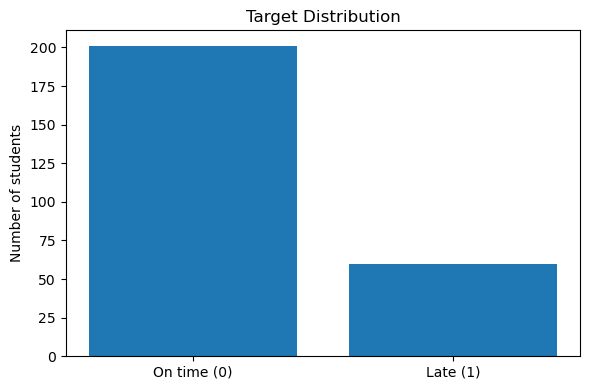

In [41]:
target_counts = (

    df[
        "late_payment"
    ]
    .value_counts()
    .sort_index()

)


fig, ax = plt.subplots(
    figsize=(6, 4)
)


ax.bar(

    [
        "On time (0)",
        "Late (1)"
    ],

    target_counts.values

)


ax.set_title(
    "Target Distribution"
)


ax.set_ylabel(
    "Number of students"
)


fig.tight_layout()

In [42]:
TARGET_FIGURE_PATH = (

    FIGURES_DIR
    /
    "target_distribution.png"

)


fig.savefig(

    TARGET_FIGURE_PATH,

    dpi=160,

    bbox_inches="tight"

)


plt.show()

## 16.3 توزيع أهم المتغيرات الرقمية

In [43]:
numeric_eda_features = [

    "gpa",

    "attendance_rate",

    "registered_hours",

    "delay_count",

    "max_delay_days",

    "on_time_payment_count",

    "semester_fee",

    "distance_from_university"
]

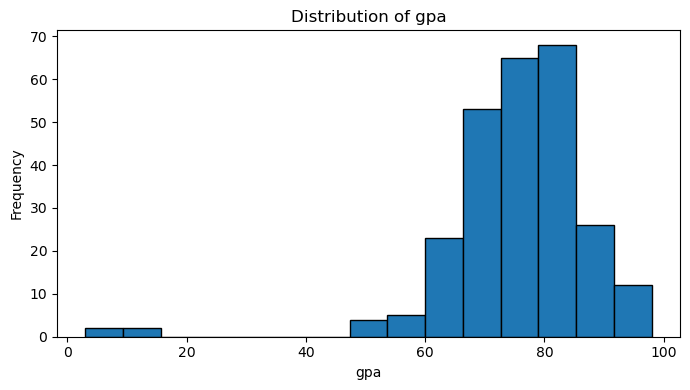

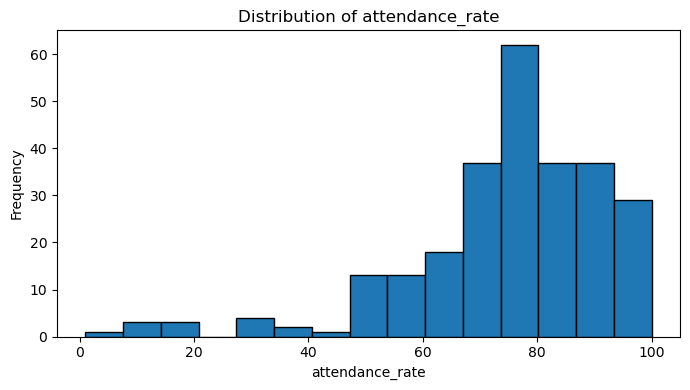

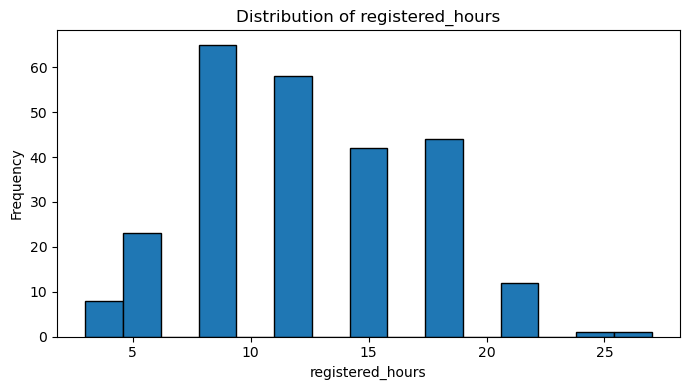

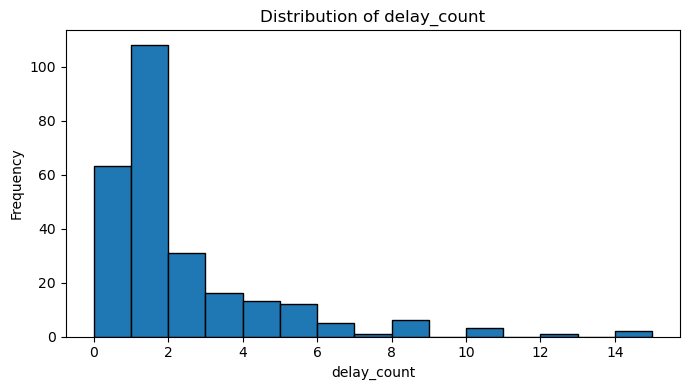

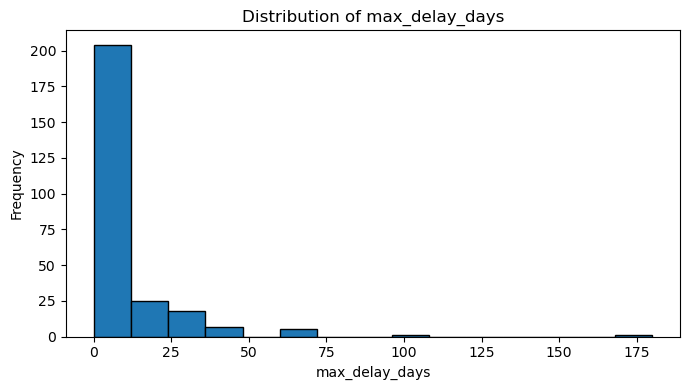

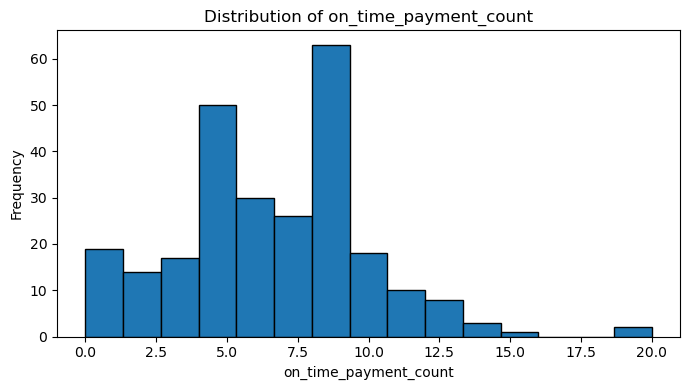

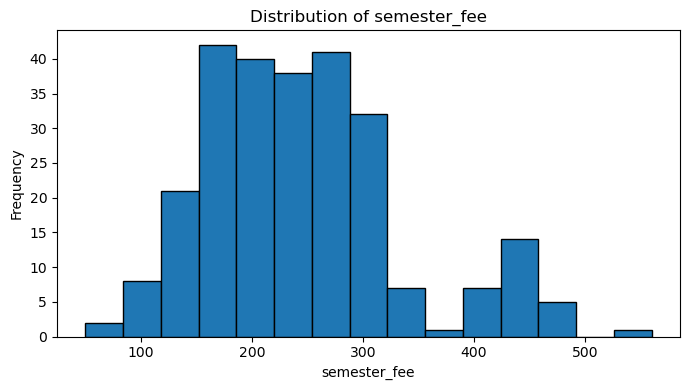

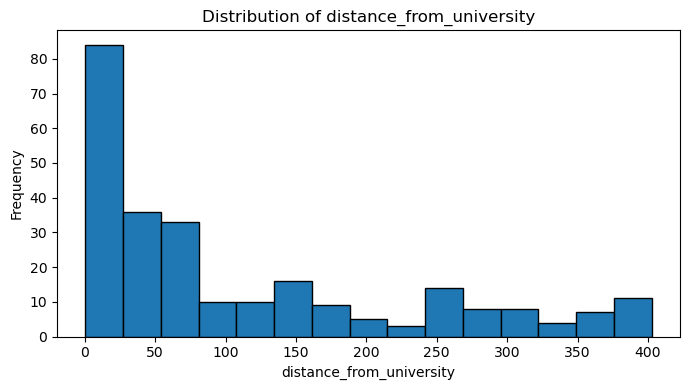

In [44]:
for col in numeric_eda_features:

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )


    ax.hist(

        df[col].dropna(),

        bins=15,

        edgecolor="black"

    )


    ax.set_title(
        f"Distribution of {col}"
    )


    ax.set_xlabel(
        col
    )


    ax.set_ylabel(
        "Frequency"
    )


    fig.tight_layout()


    plt.show()

## 16.4 مقارنة المتغيرات الرقمية بين المتأخرين وغير المتأخرين

In [45]:
boxplot_features = [

    "gpa",

    "attendance_rate",

    "delay_count",

    "max_delay_days",

    "on_time_payment_count",

    "semester_fee",

    "distance_from_university"
]

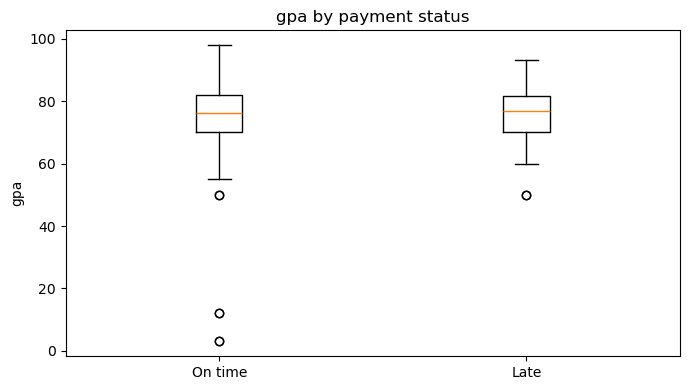

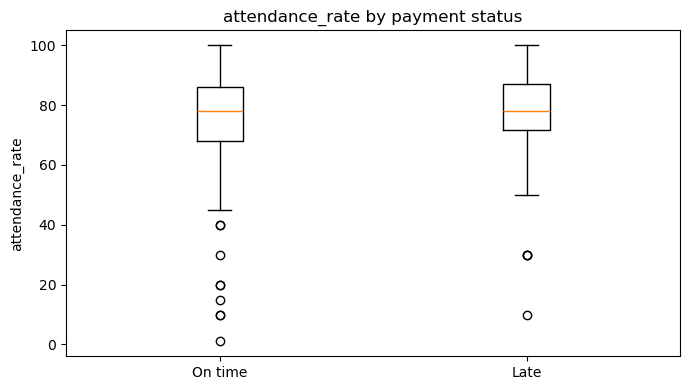

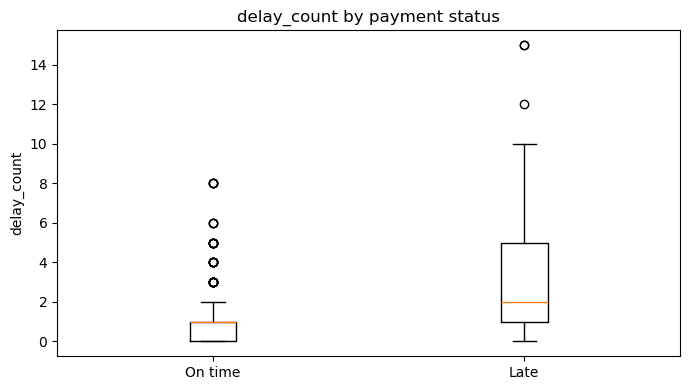

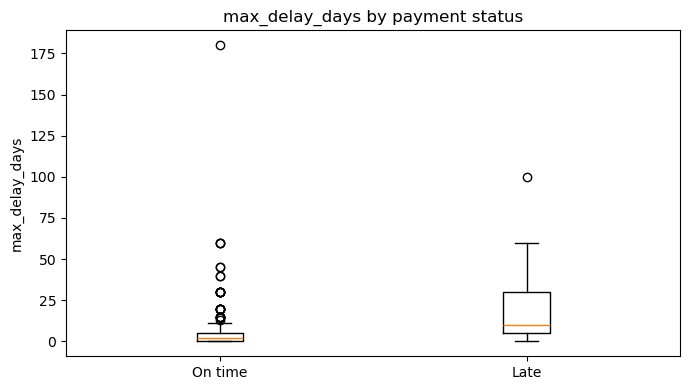

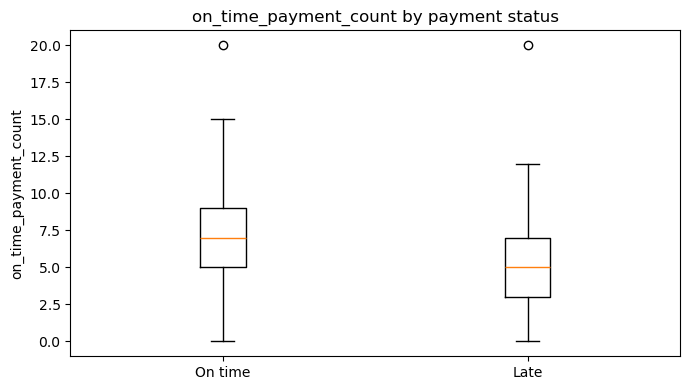

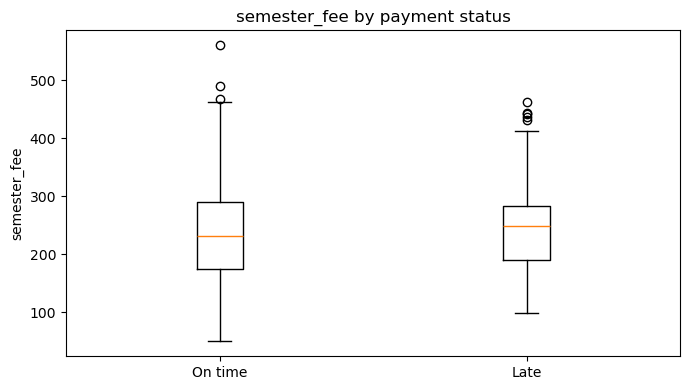

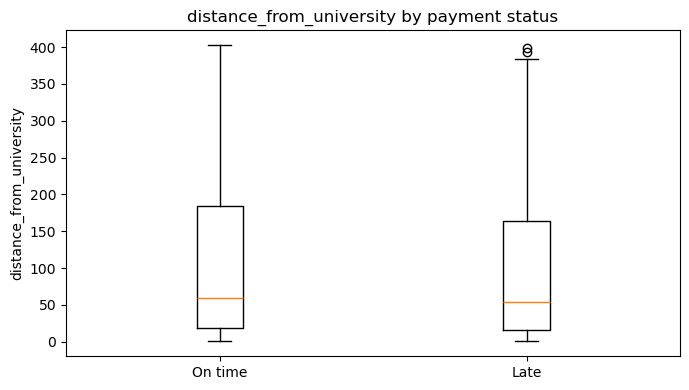

In [48]:
for col in boxplot_features:

    on_time_values = df.loc[
        df["late_payment"] == 0,
        col
    ].dropna()

    late_values = df.loc[
        df["late_payment"] == 1,
        col
    ].dropna()


    fig, ax = plt.subplots(
        figsize=(7, 4)
    )


    ax.boxplot(
        [
            on_time_values,
            late_values
        ]
    )


    ax.set_xticks(
        [1, 2]
    )


    ax.set_xticklabels(
        [
            "On time",
            "Late"
        ]
    )


    ax.set_title(
        f"{col} by payment status"
    )


    ax.set_ylabel(
        col
    )


    fig.tight_layout()


    plt.show()

## 16.5 العلاقة بين المتغيرات الفئوية والتأخر

In [49]:
categorical_eda_features = [

    "previous_payment_delay",

    "previous_unpaid_fees",

    "works_while_studying",

    "payment_responsible",

    "family_monthly_income",

    "study_year",

    "housing"
]

In [50]:
for col in categorical_eda_features:

    table = pd.crosstab(

        df[col],

        df[
            "late_payment"
        ],

        normalize="index"

    ).rename(

        columns={

            0:
                "on_time_ratio",

            1:
                "late_ratio"

        }

    )


    print(
        "\n" + "=" * 80
    )


    print(col)


    display(

        table.sort_values(

            "late_ratio",

            ascending=False

        ).round(4)

    )


previous_payment_delay


late_payment,on_time_ratio,late_ratio
previous_payment_delay,,
نعم,0.7136,0.2864
لا,0.9516,0.0484



previous_unpaid_fees


late_payment,on_time_ratio,late_ratio
previous_unpaid_fees,,
نعم,0.4872,0.5128
لا,0.8198,0.1802



works_while_studying


late_payment,on_time_ratio,late_ratio
works_while_studying,,
نعم,0.7288,0.2712
لا,0.8042,0.1958



payment_responsible


late_payment,on_time_ratio,late_ratio
payment_responsible,,
الطالب,0.7196,0.2804
الأسرة(اب-أم),0.7949,0.2051
الطالب والأسرة,0.8276,0.1724
منحة/جهة داعمة,0.8750,0.1250



family_monthly_income


late_payment,on_time_ratio,late_ratio
family_monthly_income,,
اكثر من 1000,0.7333,0.2667
بين 100 و 200,0.7377,0.2623
بين 500 و 1000,0.7500,0.2500
بين 200 و 500,0.7798,0.2202
اقل من 100,0.8696,0.1304



study_year


late_payment,on_time_ratio,late_ratio
study_year,,
ثالثة,0.7407,0.2593
رابعة,0.7407,0.2593
ثانية,0.7600,0.2400
أولى,0.7857,0.2143
خامسة,0.8611,0.1389



housing


late_payment,on_time_ratio,late_ratio
housing,,
إيجار,0.0000,1.0000
مع الأقارب,0.6250,0.3750
سكن جامعي,0.7500,0.2500
ايجار,0.7624,0.2376
ملك,0.8000,0.2000
مخيم,0.8333,0.1667


## 16.6 مصفوفة الارتباط

In [51]:
corr_df = (

    df.select_dtypes(
        include=np.number
    )

    .drop(

        columns=[
            "late_payment"
        ],

        errors="ignore"

    )

)


corr_matrix = corr_df.corr()

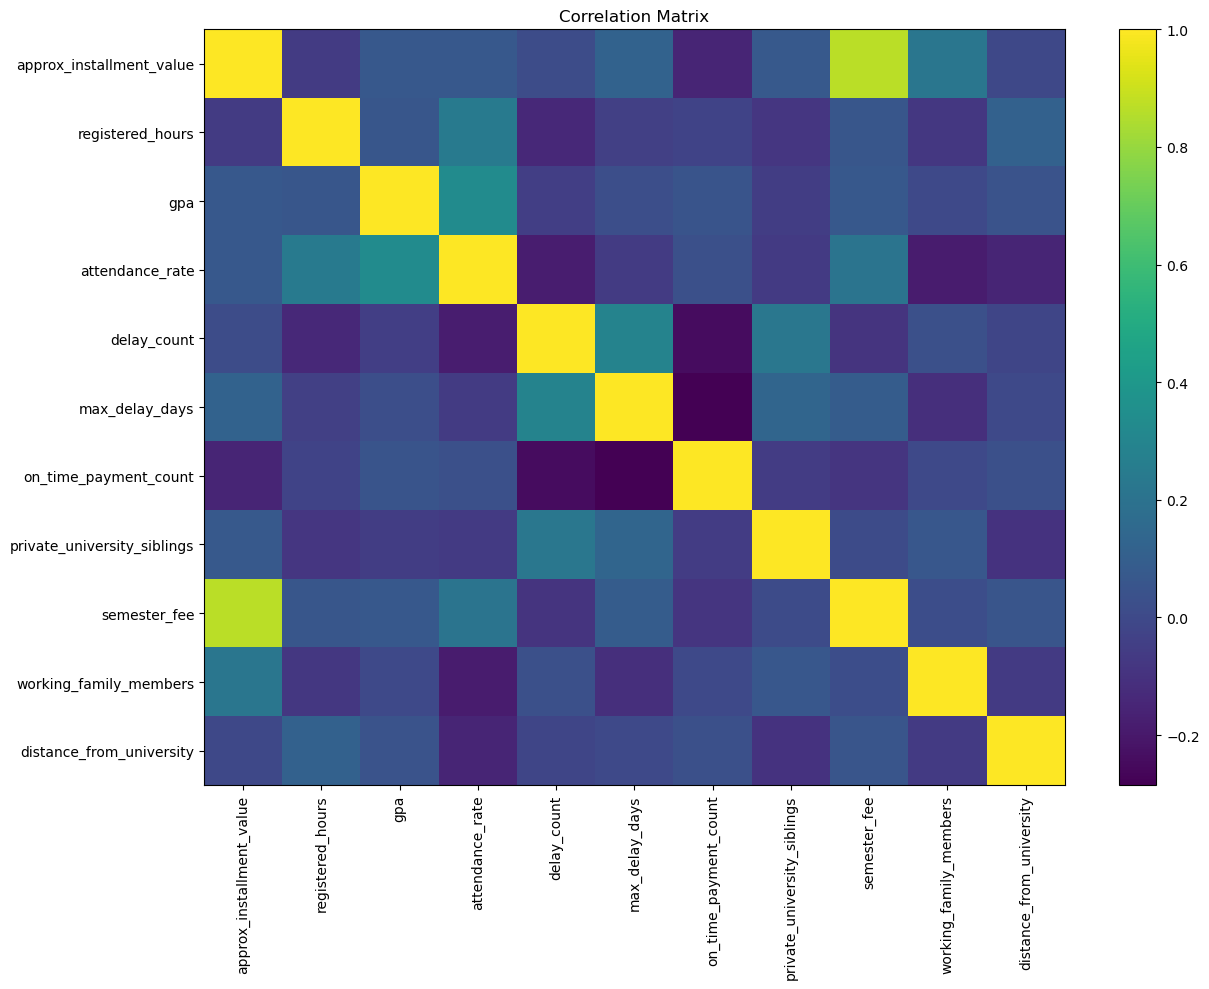

In [52]:
fig, ax = plt.subplots(
    figsize=(13, 10)
)


image = ax.imshow(

    corr_matrix,

    aspect="auto"

)


fig.colorbar(
    image,
    ax=ax
)


ax.set_xticks(
    range(
        len(
            corr_matrix.columns
        )
    )
)


ax.set_yticks(
    range(
        len(
            corr_matrix.columns
        )
    )
)


ax.set_xticklabels(

    corr_matrix.columns,

    rotation=90

)


ax.set_yticklabels(
    corr_matrix.columns
)


ax.set_title(
    "Correlation Matrix"
)


fig.tight_layout()


plt.show()

# 17. حفظ نسخة البيانات المنظفة

In [53]:
CLEAN_DATA_PATH = (

    DATA_DIR
    /
    "dataset-students-cleaned.csv"

)


df.to_csv(

    CLEAN_DATA_PATH,

    index=False,

    encoding="utf-8-sig"

)


print(
    CLEAN_DATA_PATH
)

C:\Users\abdalmohaymen\Downloads\mlproject\data\dataset-students-cleaned.csv


# 18. تحديد Features و Target

سنحذف:

- timestamp
- الهدف النصي الأصلي
- late_payment من X

In [54]:
DROP_FROM_FEATURES = [

    "timestamp",

    "paid_last_installment_on_time",

    "late_payment"

]

In [55]:
X = df.drop(

    columns=
        DROP_FROM_FEATURES

)


y = (

    df[
        "late_payment"
    ]
    .astype(int)

)


print(
    "X Shape:",
    X.shape
)


print(
    "y Shape:",
    y.shape
)

X Shape: (261, 20)
y Shape: (261,)


In [56]:
X.head()

,branch,approx_installment_value,payment_responsible,works_while_studying,governorate,registered_hours,previous_payment_delay,gpa,attendance_rate,delay_count,max_delay_days,on_time_payment_count,family_monthly_income,private_university_siblings,semester_fee,study_year,working_family_members,previous_unpaid_fees,housing,distance_from_university
0,كلية الهندسة المعلوماتية,NaN,الطالب,نعم,إدلب,6.0,نعم,65.0,50.0,2.0,10.0,10.0,بين 100 و 200,1.000000,150.0,خامسة,2.0,نعم,ملك,100.0
1,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),نعم,حلب,9.0,نعم,70.0,90.0,3.0,2.0,10.0,بين 100 و 200,1.000000,150.0,خامسة,1.0,لا,ملك,3.0
2,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),لا,حلب,9.0,نعم,75.0,75.0,1.0,1.0,6.0,اقل من 100,1.000000,400.0,ثالثة,1.0,لا,ملك,5.0
3,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),لا,إدلب,18.0,نعم,85.0,95.0,1.0,3.0,8.0,بين 200 و 500,0.000001,200.0,رابعة,2.0,لا,ايجار,7.0
4,كلية الهندسة المعلوماتية,NaN,الطالب,نعم,حلب,NaN,نعم,80.0,40.0,2.0,15.0,5.0,بين 200 و 500,1.000000,400.0,ثالثة,3.0,لا,ملك,40.0


# 19. تحديد Features الرقمية والفئوية

In [57]:
categorical_features = (

    X.select_dtypes(
        include="object"
    )
    .columns
    .tolist()

)


numeric_features = (

    X.select_dtypes(
        exclude="object"
    )
    .columns
    .tolist()

)

In [58]:
print(
    "Categorical Features:"
)


for col in categorical_features:

    print(
        "-",
        col
    )


print(
    "\nNumeric Features:"
)


for col in numeric_features:

    print(
        "-",
        col
    )

Categorical Features:
- branch
- payment_responsible
- works_while_studying
- governorate
- previous_payment_delay
- family_monthly_income
- study_year
- previous_unpaid_fees
- housing

Numeric Features:
- approx_installment_value
- registered_hours
- gpa
- attendance_rate
- delay_count
- max_delay_days
- on_time_payment_count
- private_university_siblings
- semester_fee
- working_family_members
- distance_from_university


# 20. تقسيم البيانات

سنستخدم:

- 80% Training
- 20% Testing

مع stratify للحفاظ على توزيع Target.

In [59]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y

)

In [60]:
print(
    "X Train:",
    X_train.shape
)


print(
    "X Test:",
    X_test.shape
)


print(
    "\nTrain Target:"
)


print(
    y_train.value_counts(
        normalize=True
    ).round(4)
)


print(
    "\nTest Target:"
)


print(
    y_test.value_counts(
        normalize=True
    ).round(4)
)

X Train: (208, 20)
X Test: (53, 20)

Train Target:
late_payment
0    0.7692
1    0.2308
Name: proportion, dtype: float64

Test Target:
late_payment
0    0.7736
1    0.2264
Name: proportion, dtype: float64


# 21. Preprocessing Pipeline

بالنسبة للبيانات الرقمية:

- تعويض Missing Values باستخدام Median.
- StandardScaler.

In [61]:
numeric_pipeline = Pipeline(

    steps=[

        (

            "imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (

            "scaler",

            StandardScaler()

        )

    ]

)

بالنسبة للبيانات الفئوية:

- تعويض Missing Values بالقيمة الأكثر تكرارًا.
- One-Hot Encoding.

In [62]:
categorical_pipeline = Pipeline(

    steps=[

        (

            "imputer",

            SimpleImputer(
                strategy="most_frequent"
            )

        ),

        (

            "onehot",

            OneHotEncoder(
                handle_unknown="ignore"
            )

        )

    ]

)

In [63]:
preprocessor = ColumnTransformer(

    transformers=[

        (

            "num",

            numeric_pipeline,

            numeric_features

        ),

        (

            "cat",

            categorical_pipeline,

            categorical_features

        )

    ]

)


preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

# 22. Baseline Model

سنستخدم DummyClassifier لمعرفة أداء نموذج لا يتعلم فعليًا من البيانات.

In [64]:
baseline_model = Pipeline(

    steps=[

        (

            "preprocessor",

            preprocessor

        ),

        (

            "model",

            DummyClassifier(
                strategy="most_frequent"
            )

        )

    ]

)

In [65]:
baseline_model.fit(

    X_train,

    y_train

)


baseline_prediction = (

    baseline_model.predict(
        X_test
    )

)

In [66]:
baseline_metrics = {

    "accuracy":

        accuracy_score(
            y_test,
            baseline_prediction
        ),

    "precision":

        precision_score(
            y_test,
            baseline_prediction,
            zero_division=0
        ),

    "recall":

        recall_score(
            y_test,
            baseline_prediction,
            zero_division=0
        ),

    "f1":

        f1_score(
            y_test,
            baseline_prediction,
            zero_division=0
        )

}


pd.DataFrame(
    [baseline_metrics]
).round(4)

,accuracy,precision,recall,f1
0,0.7736,0.0,0.0,0.0


# 23. إعداد Cross Validation

In [67]:
cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=RANDOM_STATE

)

In [68]:
scoring = {

    "accuracy":
        "accuracy",

    "precision":
        "precision",

    "recall":
        "recall",

    "f1":
        "f1",

    "roc_auc":
        "roc_auc"

}

# 24. النماذج المستخدمة

سنستخدم ثلاثة نماذج:

1. Logistic Regression
2. Random Forest
3. Support Vector Machine

In [69]:
candidate_models = {

    "Logistic Regression":

        LogisticRegression(

            max_iter=3000,

            class_weight="balanced",

            random_state=
                RANDOM_STATE

        ),


    "Random Forest":

        RandomForestClassifier(

            n_estimators=300,

            class_weight="balanced",

            random_state=
                RANDOM_STATE,

            n_jobs=1

        ),


    "SVM":

        SVC(

            probability=True,

            class_weight="balanced",

            random_state=
                RANDOM_STATE

        )

}

## 24.1 مقارنة النماذج قبل ضبط Hyperparameters

In [70]:
initial_cv_rows = []


for model_name, model in candidate_models.items():


    pipeline = Pipeline(

        steps=[

            (

                "preprocessor",

                preprocessor

            ),

            (

                "model",

                model

            )

        ]

    )


    scores = cross_validate(

        pipeline,

        X_train,

        y_train,

        cv=cv,

        scoring=scoring,

        n_jobs=1

    )


    initial_cv_rows.append({

        "model":
            model_name,

        "accuracy":
            scores[
                "test_accuracy"
            ].mean(),

        "precision":
            scores[
                "test_precision"
            ].mean(),

        "recall":
            scores[
                "test_recall"
            ].mean(),

        "f1":
            scores[
                "test_f1"
            ].mean(),

        "roc_auc":
            scores[
                "test_roc_auc"
            ].mean()

    })

In [71]:
initial_model_comparison = (

    pd.DataFrame(
        initial_cv_rows
    )

    .sort_values(

        "f1",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


initial_model_comparison.round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,SVM,0.7265,0.4337,0.5644,0.4885,0.7401
1,Logistic Regression,0.7264,0.4232,0.5689,0.4821,0.7168
2,Random Forest,0.7451,0.4467,0.4378,0.4405,0.7744


# 25. Hyperparameter Tuning

سنبحث عن أفضل إعدادات لكل نموذج.

وسيكون F1-score هو المقياس المستخدم في اختيار الإعداد الأفضل.

In [72]:
search_spaces = {


    "Logistic Regression":

    (

        LogisticRegression(

            max_iter=3000,

            class_weight="balanced",

            random_state=
                RANDOM_STATE

        ),

        {

            "model__C": [

                0.1,

                0.5,

                1,

                2,

                5,

                10

            ]

        }

    ),


    "Random Forest":

    (

        RandomForestClassifier(

            class_weight="balanced",

            random_state=
                RANDOM_STATE,

            n_jobs=1

        ),

        {

            "model__n_estimators": [

                200,

                400

            ],


            "model__max_depth": [

                None,

                5,

                10

            ],


            "model__min_samples_leaf": [

                1,

                2,

                4

            ]

        }

    ),


    "SVM":

    (

        SVC(

            probability=True,

            class_weight="balanced",

            random_state=
                RANDOM_STATE

        ),

        {

            "model__C": [

                0.5,

                1,

                2,

                5

            ],


            "model__gamma": [

                "scale",

                "auto"

            ]

        }

    )

}

In [73]:
grid_search_results = []

best_estimators = {}

best_params_by_model = {}

In [74]:
for model_name, (
    model,
    param_grid
) in search_spaces.items():


    print(
        "=" * 80
    )


    print(
        "Tuning:",
        model_name
    )


    pipeline = Pipeline(

        steps=[

            (

                "preprocessor",

                preprocessor

            ),

            (

                "model",

                model

            )

        ]

    )


    grid = GridSearchCV(

        estimator=pipeline,

        param_grid=param_grid,

        scoring="f1",

        cv=cv,

        n_jobs=1,

        refit=True

    )


    grid.fit(

        X_train,

        y_train

    )


    best_estimators[
        model_name
    ] = grid.best_estimator_


    best_params_by_model[
        model_name
    ] = grid.best_params_


    grid_search_results.append({

        "model":
            model_name,

        "best_cv_f1":
            grid.best_score_,

        "best_params":
            grid.best_params_

    })


    print(
        "Best F1:",
        round(
            grid.best_score_,
            4
        )
    )


    print(
        "Best Parameters:"
    )


    print(
        grid.best_params_
    )

Tuning: Logistic Regression
Best F1: 0.5225
Best Parameters:
{'model__C': 0.1}
Tuning: Random Forest
Best F1: 0.5729
Best Parameters:
{'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Tuning: SVM
Best F1: 0.5643
Best Parameters:
{'model__C': 0.5, 'model__gamma': 'auto'}


In [75]:
grid_results_df = (

    pd.DataFrame(
        grid_search_results
    )

    .sort_values(

        "best_cv_f1",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


grid_results_df

,model,best_cv_f1,best_params
0,Random Forest,0.572870,"{'model__max_depth': 5, 'model__min_samples_le..."
1,SVM,0.564286,"{'model__C': 0.5, 'model__gamma': 'auto'}"
2,Logistic Regression,0.522485,{'model__C': 0.1}


# 26. المقارنة النهائية بين النماذج

بعد الحصول على أفضل Hyperparameters لكل نموذج، سنعيد تقييم النماذج الثلاثة باستخدام Cross Validation.

هذه هي النتائج التي ستُحفظ لاحقًا للواجهة.

In [76]:
final_comparison_rows = []

In [77]:
for model_name, tuned_model in best_estimators.items():


    scores = cross_validate(

        tuned_model,

        X_train,

        y_train,

        cv=cv,

        scoring=scoring,

        n_jobs=1

    )


    final_comparison_rows.append({

        "model":
            model_name,


        "accuracy":
            scores[
                "test_accuracy"
            ].mean(),


        "precision":
            scores[
                "test_precision"
            ].mean(),


        "recall":
            scores[
                "test_recall"
            ].mean(),


        "f1":
            scores[
                "test_f1"
            ].mean(),


        "roc_auc":
            scores[
                "test_roc_auc"
            ].mean(),


        "accuracy_std":
            scores[
                "test_accuracy"
            ].std(),


        "precision_std":
            scores[
                "test_precision"
            ].std(),


        "recall_std":
            scores[
                "test_recall"
            ].std(),


        "f1_std":
            scores[
                "test_f1"
            ].std(),


        "roc_auc_std":
            scores[
                "test_roc_auc"
            ].std()

    })

In [137]:
final_model_comparison = (

    pd.DataFrame(
        final_comparison_rows
    )

    .sort_values(

        "f1",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


final_model_comparison.round(4)

,model,accuracy,precision,recall,f1,roc_auc,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
0,Random Forest,0.7553,0.4790,0.7133,0.5729,0.7730,0.0747,0.1049,0.1678,0.1286,0.0889
1,SVM,0.7505,0.4687,0.7133,0.5643,0.7603,0.0913,0.1287,0.2325,0.1640,0.1279
2,Logistic Regression,0.7312,0.4377,0.6511,0.5225,0.7597,0.0612,0.0979,0.1790,0.1280,0.1348


# 27. رسم مقارنة أداء النماذج

In [79]:
comparison_plot_data = (

    final_model_comparison

    .set_index(
        "model"
    )[

        [

            "accuracy",

            "precision",

            "recall",

            "f1"

        ]

    ]

)

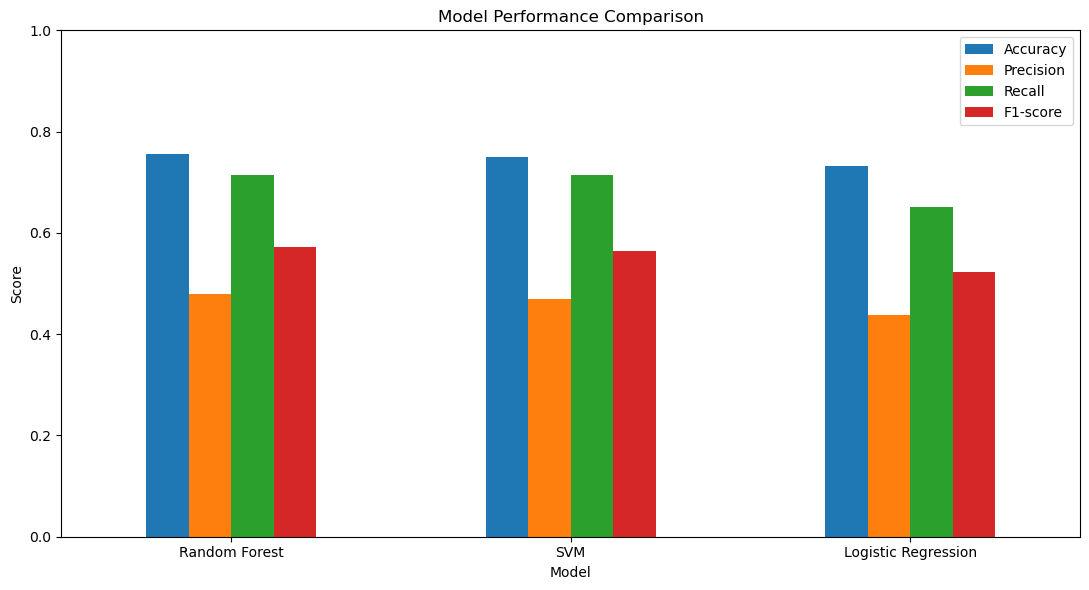

In [80]:
ax = comparison_plot_data.plot(

    kind="bar",

    figsize=(11, 6)

)


ax.set_title(
    "Model Performance Comparison"
)


ax.set_xlabel(
    "Model"
)


ax.set_ylabel(
    "Score"
)


ax.set_ylim(
    0,
    1
)


plt.xticks(
    rotation=0
)


plt.legend(

    [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score"

    ]

)


plt.tight_layout()

In [81]:
MODEL_COMPARISON_FIGURE = (

    FIGURES_DIR
    /
    "model_comparison.png"

)


plt.savefig(

    MODEL_COMPARISON_FIGURE,

    dpi=160,

    bbox_inches="tight"

)


plt.show()

<Figure size 640x480 with 0 Axes>

# 28. اختيار النموذج الأفضل

سيتم اختيار النموذج صاحب أعلى F1-score.

In [83]:
best_model_name = (

    final_model_comparison
    .loc[
        0,
        "model"
    ]

)


best_model = (

    best_estimators[
        best_model_name
    ]

)

In [84]:
print(
    "أفضل نموذج:"
)


print(
    best_model_name
)


print(
    "\nF1:"
)


print(

    round(

        final_model_comparison
        .loc[
            0,
            "f1"
        ],

        4

    )

)


print(
    "\nBest Parameters:"
)


print(

    best_params_by_model[
        best_model_name
    ]

)

أفضل نموذج:
Random Forest

F1:
0.5729

Best Parameters:
{'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


# 29. حفظ نتائج مقارنة النماذج

سيستخدم الـ Frontend هذا الملف لعرض مقارنة النماذج فقط.

القرار النهائي سيأتي من أفضل نموذج وحده.

In [85]:
comparison_data = {

    "selection_metric":
        "f1",

    "comparison_method":
        "5-fold stratified cross-validation on training set",

    "best_model":
        best_model_name,

    "models":
        []

}

In [86]:
for _, row in final_model_comparison.iterrows():


    comparison_data[
        "models"
    ].append({

        "name":
            row["model"],


        "accuracy":

            round(
                float(
                    row[
                        "accuracy"
                    ]
                ),
                4
            ),


        "precision":

            round(
                float(
                    row[
                        "precision"
                    ]
                ),
                4
            ),


        "recall":

            round(
                float(
                    row[
                        "recall"
                    ]
                ),
                4
            ),


        "f1":

            round(
                float(
                    row[
                        "f1"
                    ]
                ),
                4
            ),


        "roc_auc":

            round(
                float(
                    row[
                        "roc_auc"
                    ]
                ),
                4
            ),


        "is_best":

            bool(

                row["model"]
                ==
                best_model_name

            )

    })

In [87]:
COMPARISON_PATH = (

    MODELS_DIR
    /
    "model_comparison.json"

)


with open(

    COMPARISON_PATH,

    "w",

    encoding="utf-8"

) as f:


    json.dump(

        comparison_data,

        f,

        ensure_ascii=False,

        indent=2

    )


print(
    "تم حفظ الملف:"
)


print(
    COMPARISON_PATH
)

تم حفظ الملف:
C:\Users\abdalmohaymen\Downloads\mlproject\models\model_comparison.json


In [88]:
comparison_data

{'selection_metric': 'f1',
 'comparison_method': '5-fold stratified cross-validation on training set',
 'best_model': 'Random Forest',
 'models': [{'name': 'Random Forest',
   'accuracy': 0.7553,
   'precision': 0.479,
   'recall': 0.7133,
   'f1': 0.5729,
   'roc_auc': 0.773,
   'is_best': True},
  {'name': 'SVM',
   'accuracy': 0.7505,
   'precision': 0.4687,
   'recall': 0.7133,
   'f1': 0.5643,
   'roc_auc': 0.7603,
   'is_best': False},
  {'name': 'Logistic Regression',
   'accuracy': 0.7312,
   'precision': 0.4377,
   'recall': 0.6511,
   'f1': 0.5225,
   'roc_auc': 0.7597,
   'is_best': False}]}

# 30. التدريب النهائي للنموذج الأفضل

سيتم تدريب النموذج الأفضل على كامل Training Set.

In [89]:
best_model.fit(

    X_train,

    y_train

)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['branch','approx_installment_value','payment_responsible',..., 'previous_unpaid_fees','housing','distance_from_university']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

In [90]:
y_pred = best_model.predict(
    X_test
)

In [91]:
y_pred = best_model.predict(
    X_test
)

In [92]:
y_proba_late = (

    best_model.predict_proba(
        X_test
    )[:, 1]

)

In [93]:
test_metrics = {


    "accuracy":

        accuracy_score(
            y_test,
            y_pred
        ),


    "precision":

        precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),


    "recall":

        recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),


    "f1":

        f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),


    "roc_auc":

        roc_auc_score(
            y_test,
            y_proba_late
        ),


    "average_precision":

        average_precision_score(
            y_test,
            y_proba_late
        )

}

In [138]:
pd.DataFrame(
    [test_metrics]
).round(4)

,accuracy,precision,recall,f1,roc_auc,average_precision
0,0.7547,0.4706,0.6667,0.5517,0.7622,0.4746


## 30.1 Classification Report

In [139]:
print(

    classification_report(

        y_test,

        y_pred,

        target_names=[

            "On Time",

            "Late"

        ],

        digits=4

    )

)

              precision    recall  f1-score   support

     On Time     0.8889    0.7805    0.8312        41
        Late     0.4706    0.6667    0.5517        12

    accuracy                         0.7547        53
   macro avg     0.6797    0.7236    0.6914        53
weighted avg     0.7942    0.7547    0.7679        53



## 30.2 Confusion Matrix

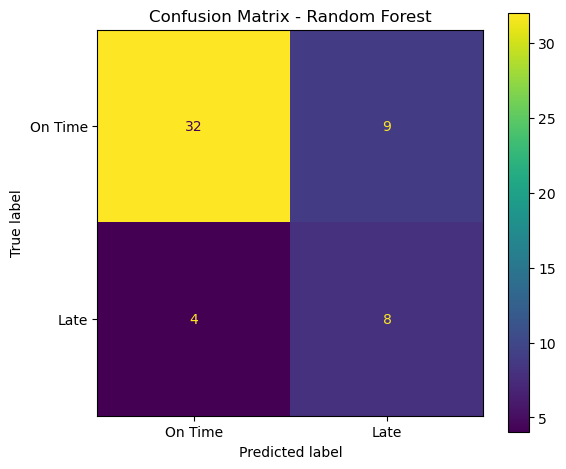

In [96]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)


ConfusionMatrixDisplay.from_predictions(

    y_test,

    y_pred,

    display_labels=[

        "On Time",

        "Late"

    ],

    ax=ax

)


ax.set_title(

    f"Confusion Matrix - {best_model_name}"

)


fig.tight_layout()

In [98]:
CONFUSION_MATRIX_PATH = (

    FIGURES_DIR
    /
    "confusion_matrix.png"

)


fig.savefig(

    CONFUSION_MATRIX_PATH,

    dpi=160,

    bbox_inches="tight"

)


plt.show()

## 30.3 ROC Curve

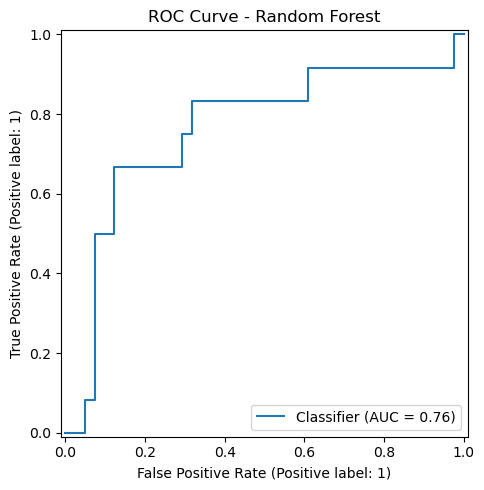

In [99]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)


RocCurveDisplay.from_predictions(

    y_test,

    y_proba_late,

    ax=ax

)


ax.set_title(

    f"ROC Curve - {best_model_name}"

)


fig.tight_layout()

In [100]:
ROC_PATH = (

    FIGURES_DIR
    /
    "roc_curve.png"

)


fig.savefig(

    ROC_PATH,

    dpi=160,

    bbox_inches="tight"

)


plt.show()

## 30.4 Precision Recall Curve

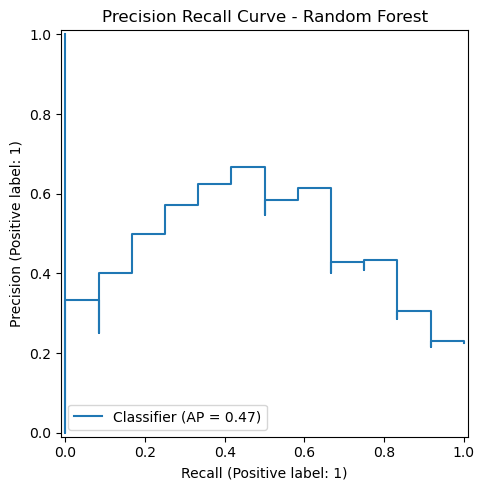

In [101]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)


PrecisionRecallDisplay.from_predictions(

    y_test,

    y_proba_late,

    ax=ax

)


ax.set_title(

    f"Precision Recall Curve - {best_model_name}"

)


fig.tight_layout()

In [102]:
PR_PATH = (

    FIGURES_DIR
    /
    "precision_recall_curve.png"

)


fig.savefig(

    PR_PATH,

    dpi=160,

    bbox_inches="tight"

)


plt.show()

# 31. تحليل أخطاء النموذج

In [103]:
error_analysis = (
    X_test.copy()
)


error_analysis[
    "actual_late"
] = y_test.values


error_analysis[
    "predicted_late"
] = y_pred


error_analysis[
    "probability_late"
] = y_proba_late


error_analysis[
    "probability_on_time"
] = (

    1
    -
    y_proba_late

)

In [104]:
false_negatives = (

    error_analysis[

        (
            error_analysis[
                "actual_late"
            ]
            == 1
        )

        &

        (
            error_analysis[
                "predicted_late"
            ]
            == 0
        )

    ]

    .sort_values(
        "probability_late"
    )

)

In [105]:
false_positives = (

    error_analysis[

        (
            error_analysis[
                "actual_late"
            ]
            == 0
        )

        &

        (
            error_analysis[
                "predicted_late"
            ]
            == 1
        )

    ]

    .sort_values(

        "probability_late",

        ascending=False

    )

)

In [106]:
print(
    "False Negatives:",
    len(
        false_negatives
    )
)


print(
    "False Positives:",
    len(
        false_positives
    )
)

False Negatives: 4
False Positives: 9


In [107]:
false_negatives.head(10)

,branch,approx_installment_value,payment_responsible,works_while_studying,governorate,registered_hours,previous_payment_delay,gpa,attendance_rate,delay_count,max_delay_days,on_time_payment_count,family_monthly_income,private_university_siblings,semester_fee,study_year,working_family_members,previous_unpaid_fees,housing,distance_from_university,actual_late,predicted_late,probability_late,probability_on_time
159,معهد نظم المعلومات الإدارية,90.0,الأسرة(اب-أم),لا,حمص,18.0,لا,72.0,72.0,0.0,0.0,5.0,بين 200 و 500,2.0,155.0,ثانية,2.0,لا,ايجار,383.7,1,0,0.088556,0.911444
16,كلية الهندسة المعلوماتية,NaN,الطالب,نعم,إدلب,3.0,نعم,70.0,30.0,2.0,2.0,20.0,بين 200 و 500,3.0,250.0,خامسة,3.0,نعم,ايجار,120.0,1,0,0.302711,0.697289
82,كلية الاقتصاد,145.0,الطالب,لا,الحسكة,9.0,نعم,92.4,100.0,1.0,3.0,9.0,اكثر من 1000,1.0,244.0,أولى,2.0,لا,مع الأقارب,156.8,1,0,0.420625,0.579375
237,كلية إدارة الأعمال,130.0,الطالب,نعم,حمص,15.0,نعم,77.6,68.0,1.0,3.0,6.0,بين 100 و 200,0.0,241.0,ثانية,3.0,نعم,ملك,398.1,1,0,0.426273,0.573727


In [108]:
false_positives.head(10)

,branch,approx_installment_value,payment_responsible,works_while_studying,governorate,registered_hours,previous_payment_delay,gpa,attendance_rate,delay_count,max_delay_days,on_time_payment_count,family_monthly_income,private_university_siblings,semester_fee,study_year,working_family_members,previous_unpaid_fees,housing,distance_from_university,actual_late,predicted_late,probability_late,probability_on_time
152,معهد أمن المعلومات والشبكات,115.0,الطالب,نعم,دمشق,15.0,نعم,59.0,75.0,8.0,60.0,5.0,بين 100 و 200,2.0,191.0,ثانية,1.0,نعم,سكن جامعي,NaN,0,1,0.775528,0.224472
93,كلية الصيدلة,205.0,منحة/جهة داعمة,لا,إدلب,12.0,نعم,85.0,84.0,4.0,15.0,9.0,بين 500 و 1000,3.0,468.0,ثانية,2.0,نعم,ايجار,18.8,0,1,0.715225,0.284775
203,معهد أمن المعلومات والشبكات,60.0,الطالب والأسرة,نعم,إدلب,18.0,نعم,90.5,89.0,8.0,5.0,7.0,بين 100 و 200,1.0,151.0,أولى,4.0,لا,مع الأقارب,10.3,0,1,0.648804,0.351196
61,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),لا,إدلب,9.0,نعم,72.5,90.0,4.0,20.0,4.0,بين 200 و 500,2.0,200.0,خامسة,1.0,لا,ملك,10.0,0,1,0.570522,0.429478
24,معهد أمن المعلومات والشبكات,NaN,الطالب,نعم,حلب,NaN,نعم,82.0,80.0,2.0,7.0,2.0,بين 100 و 200,1.0,150.0,ثانية,2.0,لا,ملك,45.0,0,1,0.562503,0.437497
45,كلية الهندسة المعلوماتية,NaN,الطالب,نعم,حلب,9.0,نعم,80.4,60.0,2.0,40.0,3.0,بين 200 و 500,1.0,170.0,ثالثة,2.0,لا,ملك,6.0,0,1,0.541448,0.458552
211,كلية الهندسة المعلوماتية,170.0,الأسرة(اب-أم),نعم,القنيطرة,15.0,نعم,79.6,69.0,2.0,20.0,5.0,بين 100 و 200,1.0,283.0,خامسة,3.0,لا,ايجار,136.1,0,1,0.530809,0.469191
231,معهد نظم المعلومات الإدارية,95.0,الأسرة(اب-أم),لا,دير الزور,9.0,نعم,86.0,81.0,2.0,30.0,1.0,بين 100 و 200,0.0,171.0,ثانية,1.0,لا,ايجار,211.3,0,1,0.521129,0.478871
71,كلية الصيدلة,180.0,الطالب,لا,طرطوس,6.0,نعم,78.0,79.0,1.0,180.0,6.0,بين 200 و 500,0.0,442.0,ثالثة,1.0,لا,ملك,268.3,0,1,0.516589,0.483411


# 32. أهم العوامل المؤثرة

سنستخدم Permutation Importance لمعرفة أهم المتغيرات بالنسبة للنموذج.

هذه الأهمية تنبؤية وليست إثباتًا لعلاقة سببية.

In [109]:
perm = permutation_importance(

    best_model,

    X_test,

    y_test,

    scoring="f1",

    n_repeats=20,

    random_state=
        RANDOM_STATE,

    n_jobs=1

)

In [110]:
feature_importance = (

    pd.DataFrame({

        "feature":

            X_test.columns,


        "importance_mean":

            perm.importances_mean,


        "importance_std":

            perm.importances_std

    })

    .sort_values(

        "importance_mean",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


feature_importance.round(4)

,feature,importance_mean,importance_std
0,max_delay_days,0.1901,0.0891
1,previous_payment_delay,0.0665,0.0545
2,delay_count,0.0282,0.0503
3,previous_unpaid_fees,0.0156,0.0086
4,private_university_siblings,0.0128,0.0468
5,on_time_payment_count,0.0118,0.0306
6,works_while_studying,0.0064,0.0088
7,governorate,0.0045,0.0100
8,attendance_rate,0.0045,0.0117
9,registered_hours,0.0021,0.0165


In [111]:
top_features = (

    feature_importance

    .head(15)

    .sort_values(
        "importance_mean"
    )

)

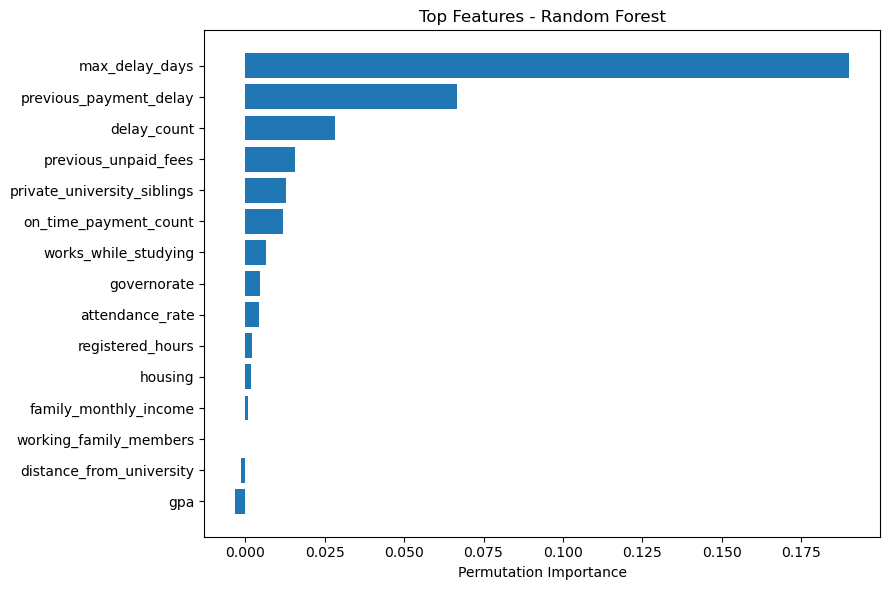

In [112]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.barh(

    top_features[
        "feature"
    ],

    top_features[
        "importance_mean"
    ]

)


ax.set_xlabel(
    "Permutation Importance"
)


ax.set_title(

    f"Top Features - {best_model_name}"

)


fig.tight_layout()

In [113]:
FEATURE_IMPORTANCE_PATH = (

    FIGURES_DIR
    /
    "feature_importance.png"

)


fig.savefig(

    FEATURE_IMPORTANCE_PATH,

    dpi=160,

    bbox_inches="tight"

)


plt.show()

# 33. حفظ النموذج النهائي

سنحفظ Pipeline كاملة، بحيث تشمل:

- Missing Values Imputer
- StandardScaler
- OneHotEncoder
- أفضل Model

وبذلك يستطيع FastAPI استخدام النموذج مباشرة.

In [114]:
MODEL_PATH = (

    MODELS_DIR
    /
    "student_payment_classifier.joblib"

)

In [115]:
joblib.dump(

    best_model,

    MODEL_PATH

)


print(
    "تم حفظ النموذج:"
)


print(
    MODEL_PATH
)

تم حفظ النموذج:
C:\Users\abdalmohaymen\Downloads\mlproject\models\student_payment_classifier.joblib


# 34. حفظ معلومات النموذج Metadata

In [117]:
metadata = {


    "model_name":

        best_model_name,


    "selection_metric":

        "f1",


    "positive_class":

        {

            "value":
                1,

            "meaning":
                "late_payment"

        },


    "target_definition":

        {

            "0":
                "paid_on_time",

            "1":
                "late_payment"

        },


    "features":

        X.columns.tolist(),


    "categorical_features":

        categorical_features,


    "numeric_features":

        numeric_features,


    "best_parameters":

        best_params_by_model[
            best_model_name
        ],


    "test_metrics":

        {

            key:
                round(
                    float(value),
                    6
                )

            for key, value
            in test_metrics.items()

        },


    "comparison_file":

        "model_comparison.json",


    "compared_models":

        final_model_comparison[
            "model"
        ].tolist(),


    "cleaning_summary":

        {

            "raw_rows":

                int(
                    len(
                        df_raw
                    )
                ),


            "final_rows":

                int(
                    len(
                        df
                    )
                ),


            "duplicates_removed":

                int(
                    duplicate_count
                ),


            "previous_payment_delay_corrections":

                int(
                    consistency_changes
                ),


            "invalid_numeric_values_converted_to_nan":

                invalid_value_report

        }

}

In [118]:
METADATA_PATH = (

    MODELS_DIR
    /
    "student_payment_classifier_metadata.json"

)

In [120]:
with open(

    METADATA_PATH,

    "w",

    encoding="utf-8"

) as f:


    json.dump(

        metadata,

        f,

        ensure_ascii=False,

        indent=2

    )


print(
    "تم حفظ Metadata:"
)


print(
    METADATA_PATH
)

تم حفظ Metadata:
C:\Users\abdalmohaymen\Downloads\mlproject\models\student_payment_classifier_metadata.json


# 35. التأكد من الملفات الناتجة

In [121]:
generated_files = [

    CLEAN_DATA_PATH,

    MODEL_PATH,

    METADATA_PATH,

    COMPARISON_PATH,

    TARGET_FIGURE_PATH,

    MODEL_COMPARISON_FIGURE,

    CONFUSION_MATRIX_PATH,

    ROC_PATH,

    PR_PATH,

    FEATURE_IMPORTANCE_PATH

]

In [122]:
for file_path in generated_files:


    if file_path.exists():

        print(
            "OK ->",
            file_path
        )


    else:

        print(
            "MISSING ->",
            file_path
        )

OK -> C:\Users\abdalmohaymen\Downloads\mlproject\data\dataset-students-cleaned.csv
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\models\student_payment_classifier.joblib
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\models\student_payment_classifier_metadata.json
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\models\model_comparison.json
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\target_distribution.png
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\model_comparison.png
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\confusion_matrix.png
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\roc_curve.png
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\precision_recall_curve.png
OK -> C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\feature_importance.png


# 36. تجربة تحميل النموذج المحفوظ

هذه الخطوة تحاكي ما سيفعله FastAPI لاحقًا.

In [123]:
loaded_model = joblib.load(
    MODEL_PATH
)

In [124]:
sample_student = (

    X_test
    .iloc[[0]]
    .copy()

)


sample_student

,branch,approx_installment_value,payment_responsible,works_while_studying,governorate,registered_hours,previous_payment_delay,gpa,attendance_rate,delay_count,max_delay_days,on_time_payment_count,family_monthly_income,private_university_siblings,semester_fee,study_year,working_family_members,previous_unpaid_fees,housing,distance_from_university
167,كلية الصيدلة,220.0,الطالب,لا,دمشق,3.0,لا,73.6,83.0,0.0,0.0,9.0,بين 500 و 1000,0.0,432.0,أولى,2.0,لا,مع الأقارب,265.8


In [125]:
sample_prediction = int(

    loaded_model.predict(
        sample_student
    )[0]

)

In [126]:
sample_late_probability = float(

    loaded_model.predict_proba(
        sample_student
    )[0, 1]

)

In [127]:
sample_on_time_probability = (

    1
    -
    sample_late_probability

)

In [128]:
print(
    "Prediction:",
    sample_prediction
)


print(
    f"Late probability: "
    f"{sample_late_probability:.2%}"
)


print(
    f"On-time probability: "
    f"{sample_on_time_probability:.2%}"
)

Prediction: 0
Late probability: 27.86%
On-time probability: 72.14%


# 37. دالة جاهزة للتنبؤ

In [129]:
def predict_student_payment(
    model,
    student_data: dict
):


    student_df = pd.DataFrame(
        [student_data]
    )


    predicted_class = int(

        model.predict(
            student_df
        )[0]

    )


    late_probability = float(

        model.predict_proba(
            student_df
        )[0, 1]

    )


    on_time_probability = (

        1
        -
        late_probability

    )


    return {

        "prediction":

            (
                "late"

                if predicted_class == 1

                else "on_time"
            ),


        "late_probability":

            late_probability,


        "on_time_probability":

            on_time_probability,


        "model":

            best_model_name

    }

In [130]:
example_student = (

    X_test
    .iloc[0]
    .to_dict()

)

In [131]:
example_student = (

    X_test
    .iloc[0]
    .to_dict()

)

In [132]:
example_result = (

    predict_student_payment(

        loaded_model,

        example_student

    )

)


example_result

{'prediction': 'on_time',
 'late_probability': 0.2786089624915299,
 'on_time_probability': 0.7213910375084701,
 'model': 'Random Forest'}

# 38. قراءة ملف مقارنة النماذج

هذا هو الملف الذي سيستخدمه Backend لاحقًا لعرض المقارنة أسفل نتيجة التنبؤ.

In [133]:
with open(

    COMPARISON_PATH,

    "r",

    encoding="utf-8"

) as f:


    saved_comparison = json.load(
        f
    )


saved_comparison

{'selection_metric': 'f1',
 'comparison_method': '5-fold stratified cross-validation on training set',
 'best_model': 'Random Forest',
 'models': [{'name': 'Random Forest',
   'accuracy': 0.7553,
   'precision': 0.479,
   'recall': 0.7133,
   'f1': 0.5729,
   'roc_auc': 0.773,
   'is_best': True},
  {'name': 'SVM',
   'accuracy': 0.7505,
   'precision': 0.4687,
   'recall': 0.7133,
   'f1': 0.5643,
   'roc_auc': 0.7603,
   'is_best': False},
  {'name': 'Logistic Regression',
   'accuracy': 0.7312,
   'precision': 0.4377,
   'recall': 0.6511,
   'f1': 0.5225,
   'roc_auc': 0.7597,
   'is_best': False}]}

# 39. التنبؤ بعدد أيام التأخير

المشروع يطلب أيضًا أنه إذا لم يدفع الطالب في الموعد، يتم تقدير عدد أيام التأخير.

لكن Dataset الحالية لا تحتوي على Target صريح يمثل عدد أيام تأخر القسط الأخير.

العمود:

max_delay_days

يمثل:

أقصى مدة زمنية تأخر بها الطالب سابقًا.

وبالتالي هو Feature تاريخية، وليس عدد أيام تأخر القسط المستهدف.

لذلك لا يصح علميًا استخدامه كـ Target للتنبؤ بعدد أيام التأخير القادم.

لبناء Regression Model صحيح نحتاج إلى عمود مثل:

last_installment_delay_days

بحيث:

- 0 إذا دفع الطالب القسط الأخير في موعده.
- عدد الأيام الفعلية إذا تأخر.

In [136]:
REGRESSION_TARGET = (
    "last_installment_delay_days"
)


if REGRESSION_TARGET in df.columns:

    print(
        "يمكن بناء Regression Model"
    )

else:

    print(
        "لم يتم بناء Regression Model لأن "
        "Target عدد أيام التأخير غير موجود "
        "في البيانات الحالية"
    )

لم يتم بناء Regression Model لأن Target عدد أيام التأخير غير موجود في البيانات الحالية


# 40. النتيجة النهائية

بعد تشغيل جميع الخلايا بنجاح يجب أن ينتج المشروع:

## data

- dataset-students-cleaned.csv

## models

- student_payment_classifier.joblib
- student_payment_classifier_metadata.json
- model_comparison.json

## research/figures

- target_distribution.png
- model_comparison.png
- confusion_matrix.png
- roc_curve.png
- precision_recall_curve.png
- feature_importance.png

## منطق النظام

### أثناء التدريب

Dataset  
↓  
Data Cleaning  
↓  
Preprocessing  
↓  
Logistic Regression  
Random Forest  
SVM  
↓  
Cross Validation  
↓  
Hyperparameter Tuning  
↓  
Model Comparison  
↓  
Best Model  

### أثناء الاستخدام

بيانات الطالب  
↓  
FastAPI  
↓  
Best Model  
↓  
Prediction  
↓  
احتمالية التأخر  
احتمالية الدفع في الموعد  

ثم أسفل النتيجة:

تنويه: تم تدريب وتقييم عدة نماذج لتعلم الآلة، وتم اعتماد النموذج الأعلى أداءً لإصدار النتيجة الحالية.

ويتم عرض مقارنة:

- Logistic Regression
- Random Forest
- SVM

باستخدام:

- Accuracy
- Precision
- Recall
- F1-score

لكن هذه المقارنة لا تدخل في القرار النهائي.

In [140]:
import sklearn
import pandas
import numpy
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.9.0
pandas: 2.1.4
numpy: 1.26.4
joblib: 1.5.3


In [141]:
import sys

print(sys.version)
print(sys.executable)

3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]
C:\Users\abdalmohaymen\anaconda3\python.exe
